In [1]:
import pandas as pd
import numpy as np
import unicodedata

# ÉTAPE 1 : Chargement des deux sources

In [2]:
df1 = pd.read_excel("Base de donnée des départs par ID.xlsx")
df2 = pd.read_excel("Départ 2025 2026.xlsx")

print("df1 :", df1.shape[0], "lignes")
print("df2 :", df2.shape[0], "lignes")

df1 : 357 lignes
df2 : 62 lignes


# ÉTAPE 2 : Nettoyage de df1 (Base historique)

In [3]:
# 2.1 Corriger AGE
df1["AGE"] = (
    (df1["Date de Départs"] - df1["DATE DE NAISSANCE"]).dt.days / 365.25
).apply(lambda x: int(x) if pd.notna(x) else np.nan)

# 2.2 Corriger les dates incohérentes (départ avant recrutement)
mask1 = df1["Date de Départs"] < df1["DATE DE RECRUTEMENT"]
df1.loc[mask1, ["DATE DE RECRUTEMENT", "Date de Départs"]] = \
    df1.loc[mask1, ["Date de Départs", "DATE DE RECRUTEMENT"]].values
print("Dates incohérentes corrigées df1 :", mask1.sum())

# 2.3 Normaliser SITUATION FAM
df1["SITUATION FAM"] = df1["SITUATION FAM"].str.strip().str.upper()

# 2.4 Normaliser Sanction
df1["Sanction"] = df1["Sanction"].replace({
    "Abandon de poste"   : "Abandon de Poste",
    "Fin de Détachement" : "Fin de détachement",
    " إعفاء Exemption "  : "Exemption",
    "exemption"          : "Exemption",
})

# 2.5 Remplir NB ENFANTS manquants
df1["NB ENFANTS"] = df1["NB ENFANTS"].fillna(0)

# 2.6 Remplacer *** par NaN puis imputer par le mode du groupe
df1 = df1.replace('***', pd.NA)

# ID-108 : imputer CENTRE D'AFFECTATION et STRUCTURE
groupe_108 = df1[
    (df1["GRADE NS"] == "TECHNICIEN QUATRIEME GRADE") &
    (df1["CATEGORIE"] == "Technicien")
]
df1.loc[df1["N°"] == "ID-108", "CENTRE D'AFFECTATION"] = \
    groupe_108["CENTRE D'AFFECTATION"].mode()[0]
df1.loc[df1["N°"] == "ID-108", "STRUCTURE"] = \
    groupe_108["STRUCTURE"].mode()[0]

# ID-134 : imputer FONCTION
groupe_134 = df1[
    (df1["GRADE NS"] == "ADMINISTRATEUR DE 1ER GRADE") &
    (df1["CATEGORIE"] == "Administrateurs")
]
df1.loc[df1["N°"] == "ID-134", "FONCTION"] = \
    groupe_134["FONCTION"].mode()[0]

print("Valeurs manquantes df1 après imputation :", df1.isnull().sum().sum())

# 2.7 Supprimer la colonne Observation
df1 = df1.drop(columns=["Observation"], errors="ignore")

Dates incohérentes corrigées df1 : 2
Valeurs manquantes df1 après imputation : 355


# ÉTAPE 3 : Nettoyage de df2 (Départ 2025-2026)

In [4]:
# 3.1 Corriger AGE
df2["AGE"] = (
    (df2["Date de Départ"] - df2["DATE DE NAISSANCE"]).dt.days / 365.25
).apply(lambda x: int(x) if pd.notna(x) else np.nan)

# 3.2 Normaliser SITUATION FAM
df2["SITUATION FAM"] = df2["SITUATION FAM"].str.strip().str.upper()

# 3.3 Normaliser Sanction
df2["Sanction"] = df2["Sanction"].replace({
    "Abandon de poste"      : "Abandon de Poste",
    "Permutation (départ)"  : "Permutation",
    "Permutation (Départ)"  : "Permutation",      # ← ajouter
    "Mutation (Départ)"     : "Mutation",
})

# 3.4 Renommer les colonnes pour harmoniser avec df1
df2 = df2.rename(columns={
    "SERVICE"        : "CENTRE D'AFFECTATION",
    "GRADE"          : "GRADE NS",
    "Date de Départ" : "Date de Départs",
})

# 3.5 Ajouter la colonne Motif absente dans df2
df2["Motif"] = "Non renseigné"

# ÉTAPE 4 : Fusion des deux sources

In [5]:
df = pd.concat([df1, df2], ignore_index=True)

# Supprimer les colonnes inutiles restantes
df = df.drop(columns=["Observation"], errors="ignore")

# Re-numéroter les identifiants de façon cohérente
df["N°"] = ["ID-" + str(i + 1) for i in range(len(df))]

print("Dataset fusionné :", df.shape)

Dataset fusionné : (419, 17)


# ÉTAPE 5 : Calcul de l'ANCIENNETÉ

In [6]:
df["DATE DE RECRUTEMENT"] = pd.to_datetime(df["DATE DE RECRUTEMENT"], errors="coerce")
df["Date de Départs"]     = pd.to_datetime(df["Date de Départs"],     errors="coerce")

df["ANCIENNETE"] = (
    (df["Date de Départs"] - df["DATE DE RECRUTEMENT"]).dt.days / 365
).round(1)

print("ANCIENNETE — min:", df["ANCIENNETE"].min(), "max:", df["ANCIENNETE"].max())


ANCIENNETE — min: 0.0 max: 44.0


# ÉTAPE 6 : Harmonisation de VILLE D'ORIGINE + création REGION

In [8]:
 #6.1 Fonction pour supprimer les accents et mettre en majuscules
def clean_anglophone(text):
    """Normalise une chaine de texte : supprime les accents et met en majuscules.
    Utilisee pour harmoniser VILLE D'ORIGINE et CIN (orthographes multiples
    trouvees dans les deux fichiers sources).
    """
    if not isinstance(text, str):
        return text
    normalized = unicodedata.normalize('NFD', text)
    cleaned = ''.join(c for c in normalized if unicodedata.category(c) != 'Mn')
    return cleaned.upper().strip()

df["VILLE D'ORIGINE"] = df["VILLE D'ORIGINE"].apply(clean_anglophone)
df["CIN"]             = df["CIN"].apply(clean_anglophone)

# 6.2 Dictionnaire de correction des doublons orthographiques
#     (fautes de frappe / variantes identifiees via df["VILLE D'ORIGINE"].unique()
#      avant harmonisation, corrigees manuellement une a une)
correct_villes = {
    "AIN BENI MATHAR"    : "AIN BENI MATHAR",
    "ELAYOUN SIDI MELOUK": "EL AIOUN SIDI MELLOUK",
    "EL AIOUN"           : "EL AIOUN SIDI MELLOUK",
    "MEKNAS"             : "MEKNES",
    "BOULEMAN"           : "BOULEMANE",
    "SAFE"               : "SALE",
    "SIDI KASEM"         : "SIDI KACEM",
    "TIFELT"             : "TIFLET",
    "BEN SLIMANE"        : "BENSLIMANE",
    "SIDI BENOUR"        : "SIDI BENNOUR",
    "BEN GUERIR"         : "BENGUERIR",
    "INZEGANE"           : "INEZGANE",
    "EL HOUCIEMA"        : "AL HOCEIMA",
    "QUEZZANE"           : "OUEZZANE",
    "OUAZZANE"           : "OUEZZANE",
    "KHNIFERA"           : "KHENIFRA",
    "OUAD ZEM"           : "OUED ZEM",
    "LAAYOUNE"           : "LAAYOUNE",
    "TETOUANE"           : "TETOUAN",
    "KHMISSAT"           : "KHEMISSET",
    "TAOUNAT"            : "TAOUNATE",
}
df["VILLE D'ORIGINE"] = df["VILLE D'ORIGINE"].replace(correct_villes)

# 6.3 Séparation LAAYOUNE vs EL AIOUN SIDI MELLOUK selon le CIN
condition_fc = (
    (df["VILLE D'ORIGINE"] == "LAAYOUNE") &
    (df["CIN"].str.startswith('FC'))
)
df.loc[condition_fc, "VILLE D'ORIGINE"] = "EL AIOUN SIDI MELLOUK"

# 6.4 Mapping VILLE D'ORIGINE → REGION
mapping_region = {
    # Oriental
    "OUJDA"               : "Oriental",
    "NADOR"               : "Oriental",
    "BERKANE"             : "Oriental",
    "TAOURIRT"            : "Oriental",
    "GUERCIF"             : "Oriental",
    "JERADA"              : "Oriental",
    "BOUARFA"             : "Oriental",
    "AHFIR"               : "Oriental",
    "FIGUIG"              : "Oriental",
    "TOUISSIT"            : "Oriental",
    "AIN BENI MATHAR"     : "Oriental",
    "EL AIOUN SIDI MELLOUK": "Oriental",
    "SAIDIA"              : "Oriental",

    # Fès-Meknès
    "FES"                 : "Fès-Meknès",
    "MEKNES"              : "Fès-Meknès",
    "IFRANE"              : "Fès-Meknès",
    "TAOUNATE"            : "Fès-Meknès",
    "SEFROU"              : "Fès-Meknès",
    "MOULAY YACOUB"       : "Fès-Meknès",
    "BOULEMANE"           : "Fès-Meknès",
    "TAZA"                : "Fès-Meknès",
    "OUISLANE"            : "Fès-Meknès",

    # Rabat-Salé-Kénitra
    "RABAT"               : "Rabat-Salé-Kénitra",
    "SALE"                : "Rabat-Salé-Kénitra",
    "TEMARA"              : "Rabat-Salé-Kénitra",
    "KENETRA"             : "Rabat-Salé-Kénitra",
    "SIDI KACEM"          : "Rabat-Salé-Kénitra",
    "KHEMISSET"           : "Rabat-Salé-Kénitra",
    "SIDI SLIMANE"        : "Rabat-Salé-Kénitra",
    "TIFLET"              : "Rabat-Salé-Kénitra",

    # Casablanca-Settat
    "CASABLANCA"          : "Casablanca-Settat",
    "SETTAT"              : "Casablanca-Settat",
    "BERRECHID"           : "Casablanca-Settat",
    "MOHAMMEDIA"          : "Casablanca-Settat",
    "EL JADIDA"           : "Casablanca-Settat",
    "BENSLIMANE"          : "Casablanca-Settat",
    "SIDI BENNOUR"        : "Casablanca-Settat",

    # Marrakech-Safi
    "MARRAKECH"           : "Marrakech-Safi",
    "SAFI"                : "Marrakech-Safi",
    "ESSAOUIRA"           : "Marrakech-Safi",
    "KELAA"               : "Marrakech-Safi",
    "DEMNATE"             : "Marrakech-Safi",
    "BENGUERIR"           : "Marrakech-Safi",

    # Souss-Massa
    "AGADIR"              : "Souss-Massa",
    "TIZNIT"              : "Souss-Massa",
    "TAROUDANT"           : "Souss-Massa",
    "GUELMIM"             : "Souss-Massa",
    "INEZGANE"            : "Souss-Massa",

    # Tanger-Tétouan-Al Hoceima
    "TANGER"              : "Tanger-Tétouan-Al Hoceima",
    "TETOUAN"             : "Tanger-Tétouan-Al Hoceima",
    "AL HOCEIMA"          : "Tanger-Tétouan-Al Hoceima",
    "IMZOUREN"            : "Tanger-Tétouan-Al Hoceima",
    "MDIQ"                : "Tanger-Tétouan-Al Hoceima",
    "CHEFCHAOUEN"         : "Tanger-Tétouan-Al Hoceima",
    "LARACHE"             : "Tanger-Tétouan-Al Hoceima",
    "OUEZZANE"            : "Tanger-Tétouan-Al Hoceima",

    # Béni Mellal-Khénifra
    "BENI MELLAL"         : "Béni Mellal-Khénifra",
    "KHENIFRA"            : "Béni Mellal-Khénifra",
    "AZROU"               : "Béni Mellal-Khénifra",
    "KHOURIBGA"           : "Béni Mellal-Khénifra",
    "FQUIH BEN SALAH"     : "Béni Mellal-Khénifra",
    "OUED ZEM"            : "Béni Mellal-Khénifra",

    # Drâa-Tafilalet
    "ERRACHIDIA"          : "Drâa-Tafilalet",
    "OUARZAZATE"          : "Drâa-Tafilalet",
    "ZAGORA"              : "Drâa-Tafilalet",
    "TINGHIR"             : "Drâa-Tafilalet",
    "RICH"                : "Drâa-Tafilalet",
    "GOULMIMA"            : "Drâa-Tafilalet",
    "ERFOUD"              : "Drâa-Tafilalet",

    # Guelmim-Oued Noun
    "GUELMIN"             : "Guelmim-Oued Noun",
    "TAN TAN"             : "Guelmim-Oued Noun",
    "SIDI IFNI"           : "Guelmim-Oued Noun",

    # Laâyoune-Sakia El Hamra
    "LAAYOUNE"            : "Laâyoune-Sakia El Hamra",

    # Dakhla-Oued Ed-Dahab
    "DAKHLA"              : "Dakhla-Oued Ed-Dahab",
}

df["REGION"] = df["VILLE D'ORIGINE"].map(mapping_region)

# Vérifier les villes non mappées
non_mappes = df[df["REGION"].isnull()]["VILLE D'ORIGINE"].unique()
if len(non_mappes) > 0:
    print("Villes non mappées :", non_mappes)
else:
    print("✅ Toutes les villes sont mappées.")

print("Distribution REGION :")
print(df["REGION"].value_counts().to_string())


✅ Toutes les villes sont mappées.
Distribution REGION :
REGION
Oriental                     154
Fès-Meknès                   118
Rabat-Salé-Kénitra            63
Drâa-Tafilalet                22
Tanger-Tétouan-Al Hoceima     18
Casablanca-Settat             17
Béni Mellal-Khénifra          11
Souss-Massa                    8
Marrakech-Safi                 7
Laâyoune-Sakia El Hamra        1


# ÉTAPE 7 : Création de la variable cible TYPE_DEPART

In [9]:
departs_volontaires = [
    'Démission',
    'Abandon de Poste',
    'Désistement',
    'Révocation',
    'Radiation'
]

df['TYPE_DEPART'] = df['Sanction'].apply(
    lambda x: 'Volontaire' if x in departs_volontaires else 'Institutionnel'
)

print("\nTYPE_DEPART :")
print(df['TYPE_DEPART'].value_counts())


TYPE_DEPART :
TYPE_DEPART
Institutionnel    229
Volontaire        190
Name: count, dtype: int64


# ÉTAPE 8 : Export final

In [10]:


colonnes_orange = [
    'N°', 'CIN', "VILLE D'ORIGINE", 'FONCTION',
    "CENTRE D'AFFECTATION", 'STRUCTURE', 'SEXE',
    'SITUATION FAM', 'NB ENFANTS', 'DATE DE NAISSANCE',
    'AGE', 'DATE DE RECRUTEMENT', 'GRADE NS', 'CATEGORIE',
    'Sanction', 'Date de Départs', 'Motif',
    'REGION', 'ANCIENNETE', 'TYPE_DEPART'
]

df_final = df[colonnes_orange]
df_final.to_csv("dataset_orange_CHU.csv", index=False)

print(f"\n✅ Fichier final sauvegardé : dataset_CHU.csv")
print(f"   Lignes    : {df_final.shape[0]}")
print(f"   Colonnes  : {df_final.shape[1]}")
print(f"   Manquants : {df_final.isnull().sum().sum()}")
print(f"   Doublons  : {df_final.duplicated().sum()}")


✅ Fichier final sauvegardé : dataset_CHU.csv
   Lignes    : 419
   Colonnes  : 20
   Manquants : 0
   Doublons  : 0


In [11]:
# Verification intermediaire : distribution de la cible juste apres sa creation
print(df['TYPE_DEPART'].value_counts())

TYPE_DEPART
Institutionnel    229
Volontaire        190
Name: count, dtype: int64


In [12]:
# Correctif applique apres le premier export (cellule precedente) :
# les departs par deces sont hors perimetre de l'etude (ni volontaire ni
# institutionnel au sens RH), on les retire avant l'export definitif.
df = df[df['Sanction'] != 'Décès']
print("Lignes restantes :", len(df))

Lignes restantes : 418


In [13]:
# Export definitif (post-filtrage des deces) : c'est ce fichier qui est
# utilise dans Orange Data Mining et dans les cellules suivantes.
df.to_csv("dataset_orange_CHU.csv", index=False)
print("✅ Fichier sauvegardé :", len(df), "lignes")

✅ Fichier sauvegardé : 418 lignes


In [14]:
# Verification rapide de l'effet de SMOTE sur un sous-ensemble reduit de
# variables (5 categorielles + 3 numeriques). Sert de premier apercu avant
# l'evaluation complete et methodologiquement correcte de la cellule suivante.
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Encoder les variables catégorielles
cols_cat = ['SEXE', 'SITUATION FAM', 'STRUCTURE', 'CATEGORIE', 'REGION']
df_enc = df.copy()
for col in cols_cat:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

X = df_enc[['AGE','ANCIENNETE','NB ENFANTS',
            'SEXE','SITUATION FAM','STRUCTURE',
            'CATEGORIE','REGION']]
y = LabelEncoder().fit_transform(df_enc['TYPE_DEPART'])

# Avant SMOTE
print("=== AVANT SMOTE ===")
print(f"Volontaire    : {(y==1).sum()}")
print(f"Institutionnel: {(y==0).sum()}")

# Appliquer SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# Après SMOTE
print("\n=== APRÈS SMOTE ===")
print(f"Volontaire    : {(y_res==1).sum()}")
print(f"Institutionnel: {(y_res==0).sum()}")
print(f"Total         : {len(y_res)}")

=== AVANT SMOTE ===
Volontaire    : 190
Institutionnel: 228

=== APRÈS SMOTE ===
Volontaire    : 228
Institutionnel: 228
Total         : 456


In [ ]:
# =============================================================
#  EVALUATION — SMOTE applique a l'interieur de chaque fold
# =============================================================
#
#
#   integrant SMOTE dans un Pipeline imblearn :
#   pour chaque fold -> SMOTE(train du fold) -> fit -> test
#  ce qui garantit que le pli de test n'est jamais vu, meme indirectement,
#  par l'etape de reequilibrage. C'est cette version qui est utilisee pour
#  
# =============================================================

import time
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from imblearn.pipeline import Pipeline as ImbPipeline   # <-- PAS sklearn.pipeline !
from imblearn.over_sampling import SMOTE

# ─────────────────────────────────────────────
#  1. CHARGEMENT & ENCODAGE
#     (identique a votre Python Script Orange, pour comparaison directe)
# ─────────────────────────────────────────────
df = pd.read_csv("dataset_orange_CHU.csv")

cols_cat = ['GRADE NS', 'SITUATION FAM', 'CATEGORIE', 'FONCTION',
            'REGION', 'SEXE', "VILLE D'ORIGINE", 'STRUCTURE']
cols_num = ['AGE', 'ANCIENNETE', 'NB ENFANTS']

df_enc = df.copy()
for col in cols_cat:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

X = df_enc[cols_num + cols_cat].fillna(0).values
y = LabelEncoder().fit_transform(df_enc['TYPE_DEPART'])
# NB : avec LabelEncoder, l'ordre alphabetique donne
#      0 = Institutionnel, 1 = Volontaire

print("Repartition des classes (avant tout traitement) :")
print(f"  Institutionnel (0) : {(y == 0).sum()}")
print(f"  Volontaire (1)     : {(y == 1).sum()}")
print()

# ─────────────────────────────────────────────
#  2. MODELES — 
# 
# ─────────────────────────────────────────────
MODELS = {
    'Random Forest'     : RandomForestClassifier(n_estimators=100, random_state=42),
    'Tree'              : DecisionTreeClassifier(random_state=42),
    'Naive Bayes'       : GaussianNB(),
    'Gradient Boosting' : GradientBoostingClassifier(n_estimators=100, random_state=42),
}

scoring = {
    'AUC'       : 'roc_auc',
    'CA'        : 'accuracy',
    'F1'        : 'f1',
    'Precision' : 'precision',
    'Recall'    : 'recall',
}

# 10 plis stratifies, comme dans le widget Test and Score
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# ─────────────────────────────────────────────
#  3. EVALUATION CORRIGEE
#     Le Pipeline imblearn garantit que :
#       - StandardScaler est ajuste UNIQUEMENT sur le train du fold
#       - SMOTE est ajuste UNIQUEMENT sur le train du fold
#       - le pli de test n'est JAMAIS vu par SMOTE
# ─────────────────────────────────────────────
print("=" * 78)
print("  RESULTATS CORRIGES (SMOTE a l'interieur de chaque fold)")
print("=" * 78)
print(f"  {'Modele':<20}{'Train(s)':>10}{'AUC':>8}{'CA':>8}{'F1':>8}{'Precision':>11}{'Recall':>9}")
print("  " + "-" * 74)

results_corriges = {}

for name, model in MODELS.items():
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote',  SMOTE(random_state=42)),
        ('model',  model),
    ])

    # n_jobs=1 pour que le temps cumule soit comparable au "Train"
    # cumulatif affiche par Orange (sequentiel)
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1)

    train_time = scores['fit_time'].sum()
    row = {k: scores[f'test_{k}'].mean() for k in scoring}
    row['Train'] = train_time
    results_corriges[name] = row

    print(f"  {name:<20}{train_time:>10.3f}{row['AUC']:>8.3f}{row['CA']:>8.3f}"
          f"{row['F1']:>8.3f}{row['Precision']:>11.3f}{row['Recall']:>9.3f}")

print()

print("=" * 78)

Repartition des classes (avant tout traitement) :
  Institutionnel (0) : 228
  Volontaire (1)     : 190

  RESULTATS CORRIGES (SMOTE a l'interieur de chaque fold)
  Modele                Train(s)     AUC      CA      F1  Precision   Recall
  --------------------------------------------------------------------------
  Random Forest            1.906   0.803   0.754   0.700      0.781    0.647
  Tree                     0.100   0.669   0.670   0.645      0.637    0.658
  Naive Bayes              0.067   0.634   0.569   0.632      0.518    0.816
  Gradient Boosting        1.590   0.766   0.725   0.684      0.726    0.663



In [ ]:
# Comptage avant/apres SMOTE sur le jeu de variables COMPLET (celui utilise
# (228/190 -> 228/228) correspondent a la Figure 10 du rapport.
# NB : ceci est un comptage global a but illustratif ; l'evaluation reelle
# des modeles (Tableau 8) utilise SMOTE par pli, cf. cellule precedente.
print("=== AVANT SMOTE ===")
print(f"Institutionnel : {(y==0).sum()}")
print(f"Volontaire     : {(y==1).sum()}")

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

print("=== APRES SMOTE ===")
print(f"Institutionnel : {(y_res==0).sum()}")
print(f"Volontaire     : {(y_res==1).sum()}")
print(f"Total          : {len(y_res)}")

=== AVANT SMOTE ===
Institutionnel : 228
Volontaire     : 190
=== APRES SMOTE ===
Institutionnel : 228
Volontaire     : 228
Total          : 456


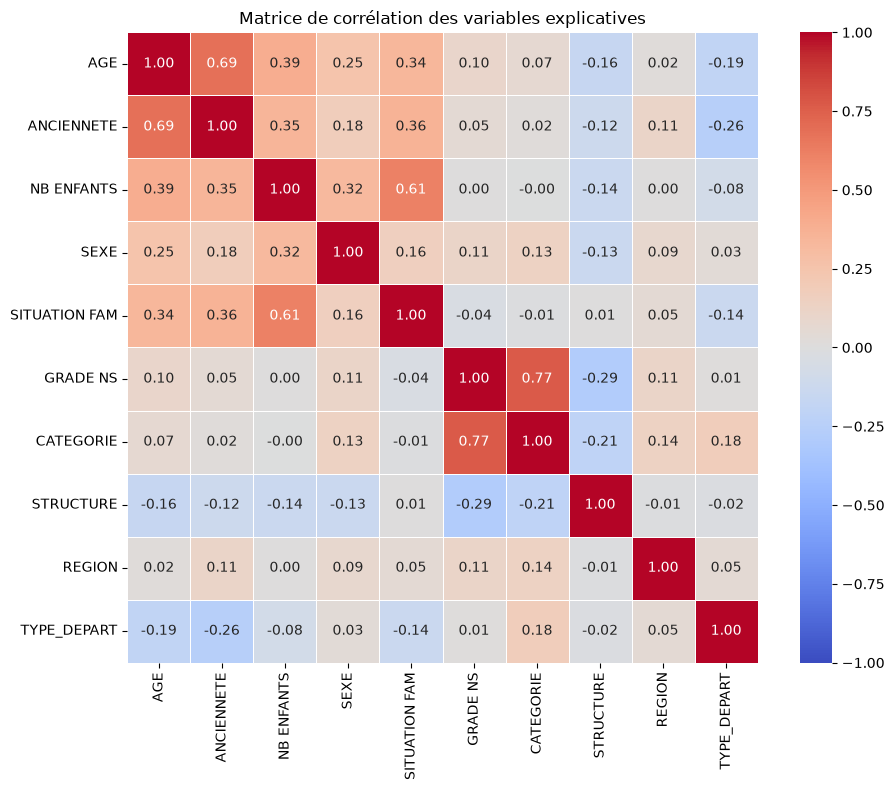

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

# Colonnes catégorielles à encoder
cat_cols = ["VILLE D'ORIGINE", 'FONCTION', "CENTRE D'AFFECTATION", 'STRUCTURE',
            'SEXE', 'SITUATION FAM', 'GRADE NS', 'CATEGORIE', 'REGION', 'TYPE_DEPART']

for col in cat_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

# Variables retenues pour la corrélation (features + cible, sans les identifiants/dates brutes)
num_cols = ['AGE', 'ANCIENNETE', 'NB ENFANTS', 'SEXE', 'SITUATION FAM',
            'GRADE NS', 'CATEGORIE', 'STRUCTURE', 'REGION', 'TYPE_DEPART']

corr_matrix = df_encoded[num_cols].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matrice de corrélation des variables explicatives")
plt.tight_layout()
plt.savefig("heatmap_correlation.png", dpi=150)
plt.show()